# 13 — stack logistique

Régression logistique par cible, sur chaque sous-ensemble non vide de `MODELS`.
Même ajustement partout : une couche linéaire par cible, log loss, pénalité L2 à 1e-3, 120 epochs.
Le checkpoint retenu est l'epoch de meilleure AUC train.

Entrées, **par cible** :

- le logit de chaque modèle du sous-ensemble
- les six slots vides (`slot_empty_unseen_rsna.csv`, 1 = slot vide au forward)
- le produit logit × slot, pour que le poids d'un modèle change quand un slot est vide

Le nombre d'ensembles est 2ⁿ − 1. Cinq modèles en donnent 31, six en donnent 63, sept en donnent 127.

Ajustement : études `fit`. Si le sous-ensemble contient le distil, les études qu'il a déjà vues sortent de ce fit.
Val : les 652, lues à chaque epoch, jamais utilisées pour choisir le checkpoint.
Gold : un chiffre par ensemble, n = 58.
Labels v3b binarisés à 0,5. L'AUC du tableau est la macro des 12 cibles, la métrique de la compétition.

Commenter une ligne de `MODELS` retire un modèle du pool.


In [ ]:
from __future__ import annotations

import sys
import time
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

%matplotlib inline
plt.rcParams["figure.dpi"] = 100

ROOT = Path.cwd() if (Path.cwd() / "checkpoints").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.nlp.lexicon import TARGETS
from src.train.metrics import macro_auc

PRED = ROOT / "data" / "hybrid_pred"

# Commenter une ligne retire le modèle de tous les ensembles.
MODELS = [
    ("ViT-k320", "hybrid_preds_unseen_rsna_vitkllrd08.csv"),
    ("v20h", "hybrid_preds_unseen_rsna__subset_v20h_dino_ep11_v3b_hybrid025.csv"),
    ("v20h-c145", "hybrid_preds_unseen_rsna__subset_v20h_dino_ep11_v3b_hybrid025_wd01_crop145.csv"),
    ("CoAt-a", "hybrid_preds_unseen_rsna__subset_coat_a_llrd08_v3b_hybrid025.csv"),
    ("CNX-r7", "hybrid_preds_unseen_rsna__subset_cnx_r7_in22k_v3b_hybrid025.csv"),
    ("v20h-distil", "hybrid_preds_unseen_rsna__subset_v20h_dino_ep11_v3b_rsna1687_distil_main_crop145.csv"),
    ("v20b", "hybrid_preds_unseen_rsna__subset_v20b_dino_ep11_v3b_hybrid025.csv"),
]
SLOTS = [
    "empty_SAG_FS", "empty_COR_FS", "empty_AX_FS",
    "empty_SAG_T1", "empty_COR_T1", "empty_AX_T1",
]
DISTIL_UIDS = (
    ROOT / "checkpoints"
    / "subset_v20h_dino_ep11_v3b_rsna1687_distil_main_crop145"
    / "train_uids.txt"
)

EPOCHS = 120
LR = 0.02
WEIGHT_DECAY = 1e-3
SEED = 42

COMBOS = [
    idxs
    for k in range(1, len(MODELS) + 1)
    for idxs in combinations(range(len(MODELS)), k)
]

print("ROOT", ROOT)
print("modèles", [name for name, _ in MODELS])
print(f"{len(MODELS)} modèles → {len(COMBOS)} ensembles")


ROOT c:\Users\sulta\Documents\RSNA-comp
modèles ['ViT-k320', 'v20h', 'v20h-c145', 'CoAt-a', 'CNX-r7', 'v20h-distil']
6 modèles → 63 ensembles


In [ ]:
def _logits(df: pd.DataFrame) -> np.ndarray:
    p = np.clip(df[[f"proba_{t}" for t in TARGETS]].to_numpy(np.float64), 1e-4, 1 - 1e-4)
    return np.log(p / (1.0 - p)).astype(np.float32)


slots = pd.read_csv(PRED / "slot_empty_unseen_rsna.csv")
uids = slots.StudyInstanceUID.astype(str).tolist()
frames = []
for name, fn in MODELS:
    df = pd.read_csv(PRED / fn)
    got = df.StudyInstanceUID.astype(str).tolist()
    if got != uids:
        raise SystemExit(f"{name} : ordre des UID différent de slot_empty")
    frames.append(df)

v3 = pd.read_csv(ROOT / "data/labels/coolin/targets_v3b.csv")
v3["StudyInstanceUID"] = v3.StudyInstanceUID.astype(str)
lab = v3.set_index("StudyInstanceUID")[TARGETS]
gold_df = pd.read_csv(ROOT / "data/csv/train.csv", usecols=["StudyInstanceUID"] + TARGETS)
gold_df["StudyInstanceUID"] = gold_df.StudyInstanceUID.astype(str)
gold_lab = gold_df.dropna(subset=TARGETS).set_index("StudyInstanceUID")[TARGETS]

rows, labeled = [], []
for uid, sp in zip(uids, slots["split"].astype(str)):
    src = gold_lab if sp == "gold" else lab
    if uid not in src.index or src.loc[uid, TARGETS].isna().any():
        labeled.append(False)
        rows.append(np.full(len(TARGETS), np.nan))
    else:
        labeled.append(True)
        rows.append(src.loc[uid, TARGETS].to_numpy(np.float64))
y_soft = np.vstack(rows)
labeled = np.asarray(labeled)
y_hard = (y_soft >= 0.5).astype(np.float64)

split = slots["split"].astype(str).to_numpy()
uid_arr = np.asarray(uids)
seen = set()
if DISTIL_UIDS.exists():
    seen = {ln.strip() for ln in DISTIL_UIDS.read_text(encoding="utf-8").splitlines() if ln.strip()}
distil_blocked = (
    np.isin(uid_arr, np.array(list(seen), dtype=object)) if seen else np.zeros(len(uids), dtype=bool)
)
fit_if_distil = (split == "fit") & labeled & ~distil_blocked
fit_no_distil = (split == "fit") & labeled
val_m = (split == "val") & labeled
gold_m = (split == "gold") & labeled

model_logits = [_logits(df) for df in frames]
model_probs = [df[[f"proba_{t}" for t in TARGETS]].to_numpy(np.float64) for df in frames]
empty = slots[SLOTS].to_numpy(np.float32)
names = [name for name, _ in MODELS]
has_distil = np.array(["distil" in fn for _, fn in MODELS])

print(
    f"études {len(uids)} | val {int(val_m.sum())} | gold {int(gold_m.sum())}"
)
print(
    f"fit sans distil {int(fit_no_distil.sum())} | fit si le distil est dans l'ensemble {int(fit_if_distil.sum())}"
)
print(
    f"retirées du fit quand le distil est dedans : {int(((split == 'fit') & distil_blocked).sum())} vues par lui, "
    f"{int(((split == 'fit') & ~labeled).sum())} sans label v3b"
)
print("taux positifs, fit sans distil")
print(pd.Series(y_hard[fit_no_distil].mean(0), index=TARGETS).round(3).to_string())


études 3142 | val 652 | gold 58
fit sans distil 2431 | fit si le distil est dans l'ensemble 1327
retirées du fit quand le distil est dedans : 1104 vues par lui, 1 sans label v3b
taux positifs, fit sans distil
ACL                 0.122
MCL                 0.032
Medial Meniscus     0.394
Lateral Meniscus    0.155
Medial OA           0.227
Lateral OA          0.107
PF OA               0.382
Effusion            0.475
Synovitis           0.078
Baker's             0.226
Contusion           0.123
Fracture            0.049


In [ ]:
def _macro_auc_rank(y: np.ndarray, s: np.ndarray) -> float:
    """Macro-AUC binaire, rangs moyens sur les ex-aequo. Même valeur que sklearn."""
    vals = []
    for c in range(y.shape[1]):
        yt = y[:, c]
        ys = s[:, c]
        n_pos = float(yt.sum())
        n = yt.size
        n_neg = n - n_pos
        if n_pos == 0.0 or n_neg == 0.0:
            continue
        order = np.argsort(ys, kind="mergesort")
        ys_s = ys[order]
        obs = np.empty(n, dtype=bool)
        obs[0] = True
        obs[1:] = ys_s[1:] != ys_s[:-1]
        dense = np.cumsum(obs) - 1
        counts = np.bincount(dense)
        starts = np.cumsum(counts) - counts
        avg = (starts + 1 + (starts + counts)) / 2.0
        ranks = np.empty(n, np.float64)
        ranks[order] = avg[dense]
        vals.append((ranks[yt == 1].sum() - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg))
    return float(np.mean(vals)) if vals else float("nan")


def _design(idxs: tuple[int, ...]) -> np.ndarray:
    z = np.stack([model_logits[i] for i in idxs], axis=1)  # (n, m, 12)
    m = z.shape[1]
    s = empty.shape[1]
    x = np.empty((len(TARGETS), z.shape[0], m + s + m * s), np.float32)
    x[:, :, :m] = np.transpose(z, (2, 0, 1))
    x[:, :, m:m + s] = empty[None]
    inter = z[:, :, None, :] * empty[:, None, :, None]
    x[:, :, m + s:] = np.transpose(inter, (3, 0, 1, 2)).reshape(len(TARGETS), z.shape[0], m * s)
    return x


def _fit_subset(idxs: tuple[int, ...]) -> dict:
    uses_distil = bool(has_distil[list(idxs)].any())
    fit_m = fit_if_distil if uses_distil else fit_no_distil
    raw = _design(idxs)
    mu = raw[:, fit_m].mean(1, keepdims=True)
    sd = raw[:, fit_m].std(1, keepdims=True)
    keep = sd > 1e-4
    sd = np.where(keep, sd, 1.0)
    x = (raw - mu) / sd * keep

    torch.manual_seed(SEED)
    xt = torch.tensor(x[:, fit_m])
    yt = torch.tensor(y_hard[fit_m].T, dtype=torch.float32)
    xv = torch.tensor(x[:, val_m])
    yv = torch.tensor(y_hard[val_m].T, dtype=torch.float32)
    weight = torch.zeros(len(TARGETS), xt.shape[-1], requires_grad=True)
    bias = torch.zeros(len(TARGETS), requires_grad=True)
    opt = torch.optim.Adam([weight, bias], lr=LR, weight_decay=WEIGHT_DECAY)
    bce = nn.BCEWithLogitsLoss()

    epoch, train_loss, val_loss, train_auc, val_auc = [], [], [], [], []
    y_fit_np = y_hard[fit_m]
    y_val_np = y_hard[val_m]
    best_auc = -1.0
    best_step = 0
    best_w = weight.detach().clone()
    best_b = bias.detach().clone()
    for step in range(EPOCHS + 1):
        with torch.no_grad():
            tr = torch.einsum("tnd,td->tn", xt, weight) + bias[:, None]
            va = torch.einsum("tnd,td->tn", xv, weight) + bias[:, None]
            tr_p = torch.sigmoid(tr).numpy().T
            va_p = torch.sigmoid(va).numpy().T
            epoch.append(step)
            train_loss.append(float(bce(tr, yt)))
            val_loss.append(float(bce(va, yv)))
            ta = _macro_auc_rank(y_fit_np, tr_p)
            train_auc.append(ta)
            val_auc.append(_macro_auc_rank(y_val_np, va_p))
            if ta > best_auc:
                best_auc = ta
                best_step = step
                best_w = weight.detach().clone()
                best_b = bias.detach().clone()
        if step == EPOCHS:
            break
        opt.zero_grad()
        logits = torch.einsum("tnd,td->tn", xt, weight) + bias[:, None]
        loss = bce(logits, yt)
        loss.backward()
        opt.step()

    with torch.no_grad():
        tr = torch.einsum("tnd,td->tn", xt, best_w) + best_b[:, None]
        va = torch.einsum("tnd,td->tn", xv, best_w) + best_b[:, None]
        tr_p = torch.sigmoid(tr).numpy().T
        va_p = torch.sigmoid(va).numpy().T
        xg = torch.tensor(x[:, gold_m])
        gold_p = torch.sigmoid(torch.einsum("tnd,td->tn", xg, best_w) + best_b[:, None]).numpy().T
    # Chiffre publié : macro_auc au checkpoint de meilleure AUC train.
    auc_train = macro_auc(y_fit_np, tr_p, TARGETS)[0]
    auc_val = macro_auc(y_val_np, va_p, TARGETS)[0]
    gold_auc = macro_auc(y_hard[gold_m], gold_p, TARGETS)[0]
    train_auc[best_step] = auc_train
    val_auc[best_step] = auc_val
    mean_probs = np.mean([model_probs[i] for i in idxs], axis=0)
    mean_val = macro_auc(y_val_np, mean_probs[val_m], TARGETS)[0]
    mean_gold = macro_auc(y_hard[gold_m], mean_probs[gold_m], TARGETS)[0]
    return {
        "ensemble": " + ".join(names[i] for i in idxs),
        "n": len(idxs),
        "distil": uses_distil,
        "fit": int(fit_m.sum()),
        "epoch": best_step,
        "loss_train": train_loss[best_step],
        "loss_val": val_loss[best_step],
        "auc_train": auc_train,
        "auc_val": auc_val,
        "moyenne": mean_val,
        "delta": auc_val - mean_val,
        "auc_gold": gold_auc,
        "moyenne_gold": mean_gold,
        "history": {
            "epoch": np.asarray(epoch),
            "train_loss": np.asarray(train_loss),
            "val_loss": np.asarray(val_loss),
            "train_auc": np.asarray(train_auc),
            "val_auc": np.asarray(val_auc),
            "best_epoch": best_step,
            "n": len(idxs),
        },
    }


rows = []
histories = {}
t0 = time.perf_counter()
for i, idxs in enumerate(COMBOS, start=1):
    row = _fit_subset(idxs)
    histories[row["ensemble"]] = row.pop("history")
    rows.append(row)
    print(
        f"{i:3d}/{len(COMBOS)}  n={row['n']}  ep {row['epoch']:3d}  fit {row['fit']:4d}  "
        f"loss {row['loss_train']:.4f}/{row['loss_val']:.4f}  "
        f"AUC {row['auc_train']:.4f}/{row['auc_val']:.4f}  {row['ensemble']}",
        flush=True,
    )

table = pd.DataFrame(rows).sort_values(
    ["auc_val", "n", "ensemble"], ascending=[False, True, True]
).reset_index(drop=True)
print(f"terminé en {time.perf_counter() - t0:.0f} s")


 1/63  n=1  fit 2431  loss 0.3298/0.3256  AUC 0.9172/0.9152  ViT-k320


 2/63  n=1  fit 2431  loss 0.3048/0.3030  AUC 0.9504/0.9537  v20h


 3/63  n=1  fit 2431  loss 0.3015/0.3004  AUC 0.9541/0.9559  v20h-c145


 4/63  n=1  fit 2431  loss 0.3407/0.3370  AUC 0.9014/0.8973  CoAt-a


 5/63  n=1  fit 2431  loss 0.3092/0.3096  AUC 0.9343/0.9291  CNX-r7


...

60/63  n=5  fit 1327  loss 0.2641/0.2669  AUC 0.9637/0.9644  ViT-k320 + v20h + CoAt-a + CNX-r7 + v20h-distil


61/63  n=5  fit 1327  loss 0.2631/0.2662  AUC 0.9645/0.9647  ViT-k320 + v20h-c145 + CoAt-a + CNX-r7 + v20h-distil


62/63  n=5  fit 1327  loss 0.2629/0.2658  AUC 0.9638/0.9648  v20h + v20h-c145 + CoAt-a + CNX-r7 + v20h-distil


63/63  n=6  fit 1327  loss 0.2614/0.2640  AUC 0.9641/0.9650  ViT-k320 + v20h + v20h-c145 + CoAt-a + CNX-r7 + v20h-distil


terminé en 82 s


                                                   ensemble  n  fit  loss_train  loss_val  auc_train  auc_val  moyenne   delta  auc_gold  moyenne_gold
ViT-k320 + v20h + v20h-c145 + CoAt-a + CNX-r7 + v20h-distil  6 1327      0.2614    0.2640     0.9641   0.9650   0.9624  0.0026    0.9153        0.9173
                ViT-k320 + v20h-c145 + CNX-r7 + v20h-distil  4 1327      0.2640    0.2673     0.9647   0.9648   0.9632  0.0017    0.9138        0.9168
         ViT-k320 + v20h + v20h-c145 + CNX-r7 + v20h-distil  5 1327      0.2622    0.2649     0.9642   0.9648   0.9636  0.0012    0.9146        0.9174
           v20h + v20h-c145 + CoAt-a + CNX-r7 + v20h-distil  5 1327      0.2629    0.2658     0.9638   0.9648   0.9633  0.0014    0.9174        0.9200
       ViT-k320 + v20h-c145 + CoAt-a + CNX-r7 + v20h-distil  5 1327      0.2631    0.2662     0.9645   0.9647   0.9613  0.0035    0.9152        0.9146
                  v20h-c145 + CoAt-a + CNX-r7 + v20h-distil  4 1327      0.2648    0.2683     

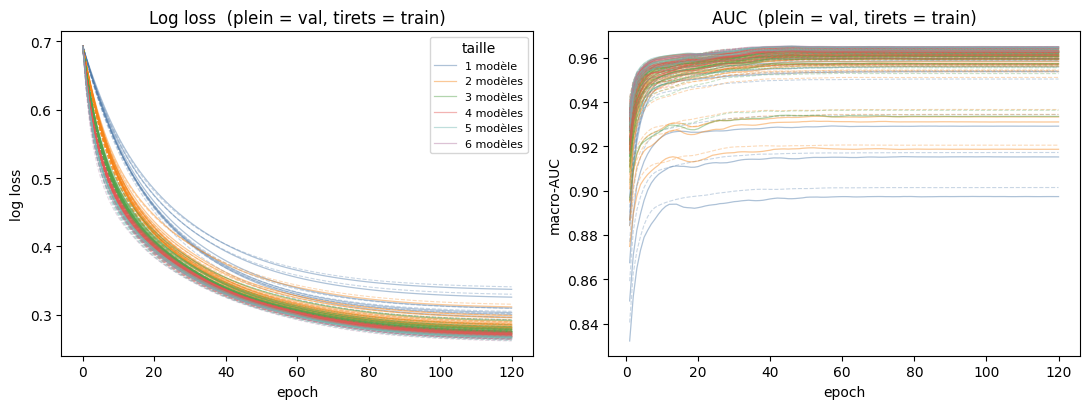

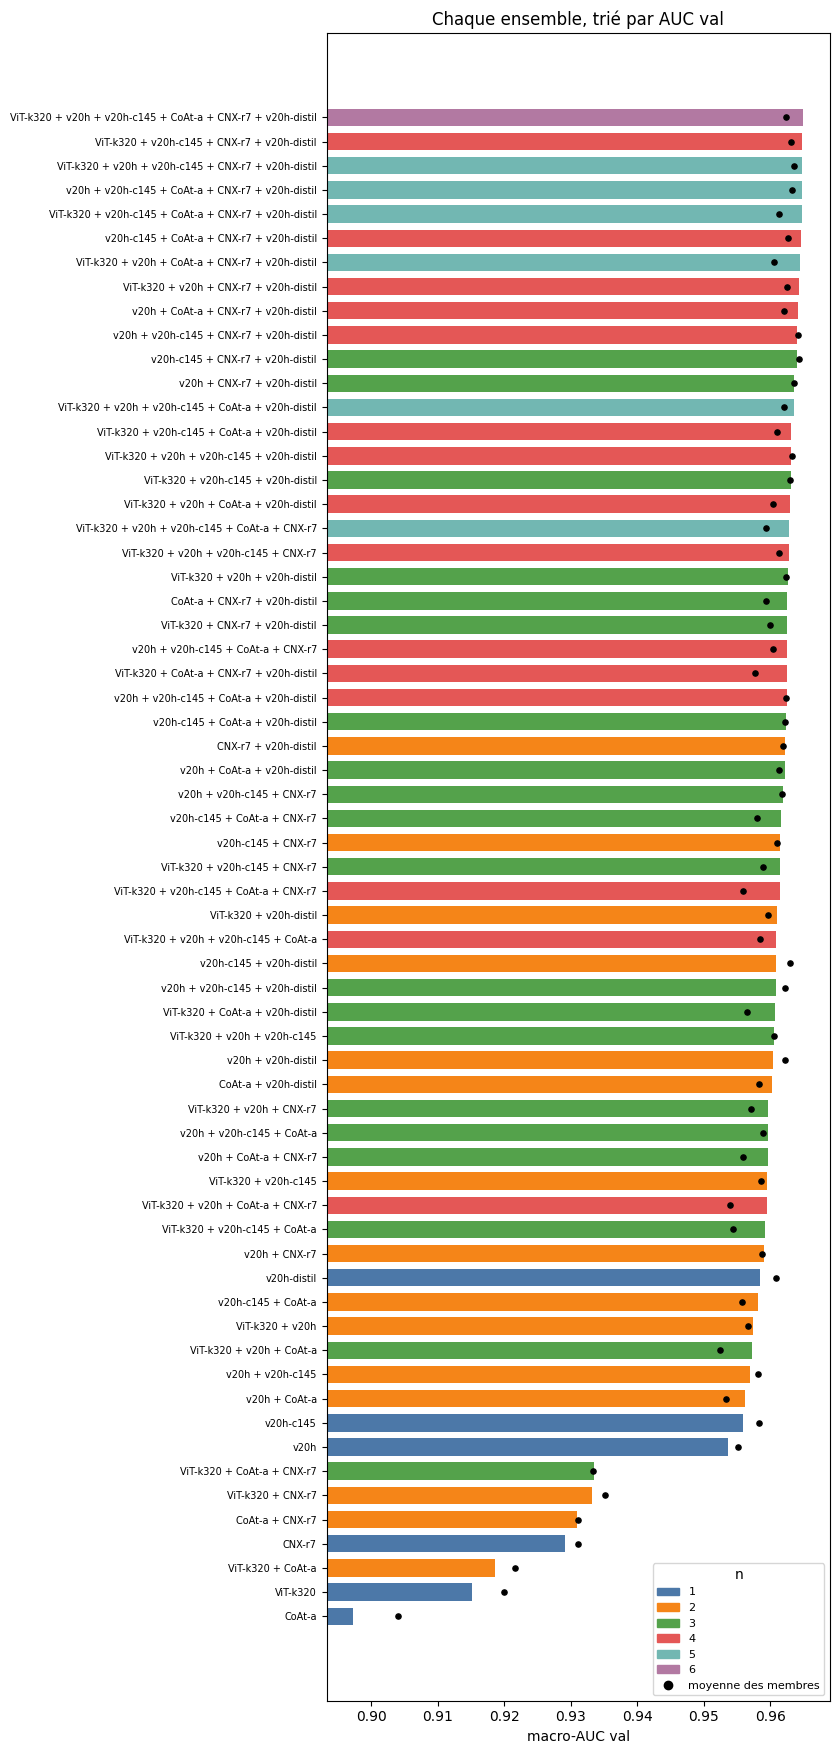

In [ ]:
cols = [
    "ensemble", "n", "epoch", "fit", "loss_train", "loss_val",
    "auc_train", "auc_val", "moyenne", "delta", "auc_gold", "moyenne_gold",
]
with pd.option_context("display.max_rows", 100, "display.width", 200, "display.max_colwidth", 120):
    print(table[cols].round(4).to_string(index=False))

top = table.iloc[0]
print(
    f"plus haut AUC val : {top.ensemble} | {top.auc_val:.4f} "
    f"(moyenne {top.moyenne:.4f}, gold {top.auc_gold:.4f})"
)
print(f"delta val > 0.01 : {int((table.delta > 0.01).sum())} / {len(table)}")

palette = {
    1: "#4c78a8", 2: "#f58518", 3: "#54a24b", 4: "#e45756",
    5: "#72b7b2", 6: "#b279a2", 7: "#9d755d",
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
seen = set()
for ensemble, hist in sorted(histories.items(), key=lambda kv: kv[1]["n"]):
    n = hist["n"]
    color = palette[n]
    label = f"{n} modèle" + ("s" if n > 1 else "")
    show = label if n not in seen else None
    seen.add(n)
    axes[0].plot(hist["epoch"], hist["train_loss"], color=color, ls="--", lw=0.8, alpha=0.3)
    axes[0].plot(hist["epoch"], hist["val_loss"], color=color, ls="-", lw=0.9, alpha=0.45, label=show)
    axes[1].plot(hist["epoch"][1:], hist["train_auc"][1:], color=color, ls="--", lw=0.8, alpha=0.3)
    axes[1].plot(hist["epoch"][1:], hist["val_auc"][1:], color=color, ls="-", lw=0.9, alpha=0.45)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("log loss")
axes[0].set_title("Log loss  (plein = val, tirets = train)")
axes[0].legend(title="taille", fontsize=8)
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("macro-AUC")
axes[1].set_title("AUC  (plein = val, tirets = train, point = epoch retenue)")
axes[1].scatter(
    [h["best_epoch"] for h in histories.values()],
    [h["train_auc"][h["best_epoch"]] for h in histories.values()],
    s=12, c="k", zorder=4,
)
fig.tight_layout()
plt.show()

order = table.sort_values(["auc_val", "n", "ensemble"], ascending=[True, False, False])
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8.5, max(6, 0.28 * len(order))))
ax.barh(y, order.auc_val, color=[palette[n] for n in order.n], height=0.72)
ax.scatter(order.moyenne, y, s=14, c="k", zorder=3, label="moyenne des membres")
ax.set_yticks(y, order.ensemble, fontsize=7)
lo = min(order.auc_val.min(), order.moyenne.min()) - 0.004
hi = max(order.auc_val.max(), order.moyenne.max()) + 0.004
ax.set_xlim(lo, hi)
ax.set_xlabel("macro-AUC val")
ax.set_title("Chaque ensemble, trié par AUC val")
handles = [Patch(color=palette[n], label=str(n)) for n in sorted(palette) if n in set(order.n)]
handles.append(Line2D([0], [0], marker="o", color="k", lw=0, label="moyenne des membres"))
ax.legend(handles=handles, title="n", loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()
